# EP2 — Agente Inteligente FTTH | Entrega técnica consolidada

**Ingeniería de Soluciones con Inteligencia Artificial (ISY0101) · Evaluación Parcial 2**

Este cuaderno concentra el flujo de **7 nodos de LangGraph**: supervisión, consulta de antecedentes, planificación, validación OTDR, orientación asistida por Gemini y almacenamiento de resultados. Es la continuación del prototipo RAG de la EP1.

**Modos diferentes, sin equivalencia de resultados:**
- `demo`: antecedentes **ficticios** y respuesta determinista. Permite probar reglas, rutas y restauración de estado sin consumir API; **no** prueba generación mediante LLM ni recuperación vectorial real.
- `real`: Excel FTTH **anonimizado** aportado por separado, **Chroma + embeddings Gemini**, y modelo Gemini para orientación. Los tickets de prueba y las mediciones OTDR **siguen siendo simulados**, aunque las herramientas de IA sean reales.

**Evidencias incluidas:** salidas obtenidas anteriormente en Google Colab el 2 de noviembre de 2026, conservadas como registro de ejecución. **No se han vuelto a ejecutar** al reorganizar este archivo. La salida extensa de Gemini se ha reducido para proteger descripciones internas, sin alterar los archivos de respaldo originales del estudiante.

**Avisos importantes:** no subir el Excel ni claves API; configurar `GOOGLE_API_KEY` en **Secretos de Colab**. Los resultados no reemplazan mediciones ni validación de técnicos en terreno. `InMemorySaver` mantiene checkpoints en la sesión, pero los JSON externos no son checkpoints persistentes completos. Las correcciones editoriales posteriores a las pruebas requieren verificación en una ejecución limpia si se busca reproducibilidad formal.

## 1. Configuración, seguridad y dependencias

El archivo conserva **`MODO = "real"`** para corresponder con las salidas históricas adjuntas. Si se desea ejecutar únicamente el flujo sin llamadas API, cambiarlo a `demo` **antes de ejecutar desde el inicio**. No cambiar de modo a mitad de sesión sin reconstruir los componentes.

**Para ejecutar en Colab:** cargar en `/content/` el Excel anonimizado con nombre indicado en la celda siguiente, habilitar el secreto `GOOGLE_API_KEY` para el cuaderno y ejecutar las celdas secuencialmente. La instalación de paquetes puede requerir reiniciar el entorno si ya había módulos OpenTelemetry cargados; tras reiniciar, volver a empezar desde la configuración. La indexación de 80 antecedentes genera llamadas a la API para embeddings.

**Versiones observadas al diagnosticar Colab:** ChromaDB 1.5.9; `langchain-chroma` 1.1.0; `opentelemetry-sdk` 1.45.2. **No equivalen a una matriz completa de dependencias fijadas**.

In [ ]:
MODO = "real"  # Cambiar a "real" solo después de probar el modo demo
MODELO_GEMINI = "gemini-3.6-flash"  # Modelo usado en el desarrollo original
MODELO_EMBEDDING = "models/gemini-embedding-001"
NOMBRE_EXCEL = "EP1_FTTH_Base_Trabajo_Inicial (2).xlsx"  # Cargar manualmente a /content/ en modo real

assert MODO in {"demo", "real"}
print("Modo seleccionado:", MODO)

Modo seleccionado: real


In [ ]:
# Instalación en Colab (no pide ni almacena credenciales)
import importlib.util
import subprocess
import sys

paquetes = []
if importlib.util.find_spec("langgraph") is None:
    paquetes.append("langgraph")
if MODO == "real":
    adicionales = [
        ("langchain_google_genai", "langchain-google-genai"),
        ("langchain_chroma", "langchain-chroma"),
        ("pandas", "pandas"),
        ("openpyxl", "openpyxl"),
    ]
    paquetes += [nombre for modulo, nombre in adicionales
                 if importlib.util.find_spec(modulo) is None]

if paquetes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *paquetes])

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
print("Bibliotecas preparadas para el modo:", MODO)

Bibliotecas preparadas para el modo: real


### 1.1. Comprobaciones previas (solo acceso, sin generar respuestas)

Las dos celdas siguientes comprueban que Colab puede leer el secreto y que el archivo local de datos está presente. **La primera no imprime la clave**. La segunda es útil en modo `real`; en modo `demo` el Excel es opcional.

In [ ]:
# EP2 - Paso 69: Verificación segura de credenciales

from google.colab import userdata

print("=== VERIFICACIÓN DE ACCESO A GEMINI ===")

try:
    clave = userdata.get("GOOGLE_API_KEY")

    if clave and clave.strip():
        print("CLAVE GEMINI CONFIGURADA CORRECTAMENTE")
    else:
        print("CLAVE GEMINI VACÍA O NO CONFIGURADA")

except Exception:
    print("NO SE PUDO ACCEDER A LA CLAVE GEMINI")
    print("Revisar Secretos de Google Colab y sus permisos.")

finally:
    if "clave" in globals():
        del clave

=== VERIFICACIÓN DE ACCESO A GEMINI ===
CLAVE GEMINI CONFIGURADA CORRECTAMENTE


In [ ]:
from pathlib import Path

archivo = Path("/content/EP1_FTTH_Base_Trabajo_Inicial (2).xlsx")

if archivo.is_file():
    print("BASE FTTH ENCONTRADA CORRECTAMENTE")
    print("Tamaño:", archivo.stat().st_size, "bytes")
else:
    print("BASE FTTH NO ENCONTRADA")

BASE FTTH ENCONTRADA CORRECTAMENTE
Tamaño: 179441 bytes


## 2. Antecedentes: fuente ficticia o RAG real

En `demo` la recuperación utiliza coincidencia de palabras en **cinco casos ficticios**, exclusivamente para mostrar el flujo. En `real` se replica la selección de categorías de EP1 (hasta 20 por categoría), se indexa con Chroma y embeddings Gemini y se recuperan los tres más próximos mediante similitud vectorial. Los históricos son **referencias**, no diagnósticos de la incidencia actual.

In [ ]:
from pathlib import Path
import os
import re
import unicodedata

# Casos inventados únicamente para validaciones sin API
CASOS_FICTICIOS = [
    {"id": "DEMO-CTO-01", "contenido": "Red FTTH. Caja CTO en mal estado. Se revisaron conectores y cables de acometida."},
    {"id": "DEMO-CTO-02", "contenido": "Red FTTH. Clientes sin servicio por posible daño de CTO. Se inspeccionó físicamente la caja."},
    {"id": "DEMO-PON-03", "contenido": "Red FTTH. Varios clientes sin servicio. Se verificaron potencias ópticas y continuidad de rama PON."},
    {"id": "DEMO-ATN-04", "contenido": "Red FTTH. Atenuación en distribución óptica. Se contrastaron niveles de potencia por tramo."},
    {"id": "DEMO-DROP-05", "contenido": "Red FTTH. Corte de cable drop. Se evaluó la continuidad desde la NAP hasta el cliente."},
]

def palabras(texto):
    texto = unicodedata.normalize("NFKD", texto.lower())
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return {p for p in re.findall(r"[a-z0-9]+", texto) if len(p) >= 3}

def recuperar_demo(descripcion, k=3):
    consulta = palabras(descripcion)
    casos = sorted(CASOS_FICTICIOS,
                   key=lambda caso: len(consulta & palabras(caso["contenido"])),
                   reverse=True)
    return [{"id": caso["id"], "fuente": "ficticia", "contenido": caso["contenido"]}
            for caso in casos[:k]]

base_vectorial = None
modelo_chat = None

if MODO == "real":
    from google.colab import userdata
    from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
    from langchain_chroma import Chroma
    import pandas as pd

    clave = userdata.get("GOOGLE_API_KEY")
    if not clave:
        raise RuntimeError("Configura GOOGLE_API_KEY en Secretos de Colab y habilita su acceso.")
    os.environ["GOOGLE_API_KEY"] = clave
    ruta_excel = Path("/content") / NOMBRE_EXCEL
    if not ruta_excel.is_file():
        raise FileNotFoundError(f"Carga primero tu Excel anonimizado en: {ruta_excel}")

    df = pd.read_excel(ruta_excel, sheet_name="FTTH_Base_Trabajo")
    categorias = ["Atenuación", "Filamento Atenuado", "Filamento cortado", "Caja CTO en mal estado"]
    muestras = [df[df["Motivo del corte"] == categoria].head(20) for categoria in categorias]
    muestra = pd.concat(muestras, ignore_index=True)
    textos = []
    metadatos = []
    for _, fila in muestra.iterrows():
        textos.append(
            f"Caso histórico: {fila['Caso_ID']}\n"
            f"Tipo de red: {fila['Tipo Red']}\n"
            f"Motivo: {fila['Motivo del corte']}\n"
            f"Distancia registrada: {fila['Distancia']} metros\n"
            f"Acción de reparación: {fila['Acción Reparación']}\n"
            f"Materiales: {fila['Materiales Ocupados']}"
        )
        metadatos.append({"caso_id": str(fila["Caso_ID"]), "tipo_fuente": "fuente_interna"})

    embeddings = GoogleGenerativeAIEmbeddings(model=MODELO_EMBEDDING)
    base_vectorial = Chroma.from_texts(
        texts=textos, embedding=embeddings, metadatas=metadatos,
        collection_name="ftth_ep2_consolidado"
    )
    modelo_chat = ChatGoogleGenerativeAI(model=MODELO_GEMINI, temperature=0)
    print("Casos internos indexados en Chroma:", len(textos))
else:
    print("Modo demostración: cinco antecedentes ficticios y SIN Gemini.")

def herramienta_consulta_rag(descripcion, cantidad=3):
    if MODO == "demo":
        return recuperar_demo(descripcion, cantidad)
    documentos = base_vectorial.similarity_search(descripcion, k=cantidad)
    return [{"id": doc.metadata.get("caso_id", "Sin ID"),
             "fuente": doc.metadata.get("tipo_fuente", "No informada"),
             "contenido": doc.page_content}
            for doc in documentos]

Casos internos indexados en Chroma: 80


### 2.1. Prueba de recuperación semántica

En `real`, se solicita una similitud vectorial y se muestran **solo identificadores anonimizados**, no el contenido completo de casos recuperados. En `demo`, la función es distinta y no demuestra RAG vectorial.

In [ ]:
# Prueba de búsqueda semántica real. La salida histórica siguiente corresponde al modo real.
if MODO == "real":
    print("=== PRUEBA DE RECUPERACIÓN SEMÁNTICA FTTH ===")
    consulta = "Clientes FTTH sin servicio, posible daño físico en caja CTO"
    resultados = herramienta_consulta_rag(consulta, cantidad=3)
    print("Modo:", MODO)
    print("Antecedentes recuperados:", len(resultados))
    for numero, caso in enumerate(resultados, start=1):
        print(f"{numero}. Caso: {caso['id']} | Fuente: {caso['fuente']}")
    assert len(resultados) == 3
    assert all(caso.get("id") for caso in resultados)
    print("\nRECUPERACIÓN RAG REAL SUPERADA")
else:
    print("Prueba 2.1 omitida: en demo se usa una búsqueda ficticia, no RAG vectorial.")

=== PRUEBA DE RECUPERACIÓN SEMÁNTICA FTTH ===
Modo: real
Antecedentes recuperados: 3
1. Caso: FTTH-0306 | Fuente: fuente_interna
2. Caso: FTTH-0405 | Fuente: fuente_interna
3. Caso: FTTH-0224 | Fuente: fuente_interna

RECUPERACIÓN RAG REAL SUPERADA


## 3. Estado, reglas de supervisión y planificación

El **supervisor** decide según si existe descripción; si falta, solicita información y **no consulta RAG ni Gemini**. Cuando existe descripción, consulta antecedentes. La planificación añade verificaciones según palabras relevantes y disponibilidad de OTDR. Esto es **decisión basada en reglas**, no elección autónoma de herramientas por el LLM.

In [ ]:
from typing import TypedDict, List, Optional, Dict, Any

class EstadoFTTH(TypedDict):
    ticket: str
    tipo_red: str
    descripcion: str
    nodo: str
    rack: str
    odf: str
    posicion: str
    distancia_otdr: Optional[float]
    historial_mediciones: List[Dict[str, Any]]
    antecedentes: List[str]
    ids_antecedentes: List[str]
    plan_revision: List[str]
    siguiente_paso: str
    validacion_otdr: Dict[str, str]
    respuesta_final: str
    archivo_estado: str

def estado_inicial(ticket, descripcion, distancia=None, historial=None):
    return {
        "ticket": ticket, "tipo_red": "FTTH", "descripcion": descripcion,
        "nodo": "No informado", "rack": "No informado", "odf": "No informado",
        "posicion": "No informada", "distancia_otdr": distancia,
        "historial_mediciones": historial or [], "antecedentes": [],
        "ids_antecedentes": [], "plan_revision": [], "siguiente_paso": "",
        "validacion_otdr": {}, "respuesta_final": "", "archivo_estado": ""
    }

def nodo_supervisor(estado: EstadoFTTH):
    decision = "consultar_rag" if (estado.get("descripcion") or "").strip() else "solicitar_informacion"
    print("Supervisor", estado["ticket"], "→", decision)
    return {"siguiente_paso": decision}

def nodo_solicitar_informacion(estado: EstadoFTTH):
    return {"respuesta_final": "Falta la descripción de la incidencia. Se solicita completar el ticket."}

def nodo_consultar_rag(estado: EstadoFTTH):
    casos = herramienta_consulta_rag(estado["descripcion"], cantidad=3)
    textos = [f"Fuente: {c['fuente']} | ID: {c['id']}\n{c['contenido']}" for c in casos]
    ids = [c["id"] for c in casos]
    print("Antecedentes recuperados:", ids)
    return {"antecedentes": textos, "ids_antecedentes": ids}

def nodo_planificar_revision(estado: EstadoFTTH):
    descripcion = estado["descripcion"].lower()
    distancia = estado["distancia_otdr"]
    plan = ["Confirmar nodo, CTO/NAP y cantidad de clientes afectados."]
    if "cto" in descripcion or "nap" in descripcion:
        plan.append("Inspeccionar físicamente CTO/NAP, puertos, conectores y cables drop.")
    if "sin servicio" in descripcion:
        plan.append("Medir potencia óptica y determinar si afecta a un cliente o rama PON.")
    if "atenuacion" in palabras(descripcion) or "degradacion" in palabras(descripcion):
        plan.append("Comparar potencias ópticas de distintos puntos de la ruta.")
    if distancia is None:
        plan.append("Evaluar si corresponde solicitar medición OTDR; no asumir distancia de falla.")
    else:
        plan.append(f"Revisar el evento OTDR reportado a {distancia:.0f} m: origen, sentido, longitud de onda y pulso.")
        plan.append("Contrastar la traza con planos y topología antes de determinar una intervención.")
    plan.append("Validar conclusiones con mediciones y personal técnico en terreno.")
    print("Verificaciones planificadas:", len(plan))
    return {"plan_revision": plan}

## 4. Validación OTDR **antes** de generar orientación

Dos distancias medidas desde **orígenes diferentes** no se pueden sumar o restar como localización confirmada de falla. La validación se hace **antes** de invocar Gemini y su advertencia se incorpora al prompt y al resultado. La verificación sigue siendo limitada: incluso mediciones desde un mismo origen necesitan confirmar fibra, evento y parámetros.

In [ ]:
def validar_contexto_mediciones_otdr(estado):
    historial = estado.get("historial_mediciones", [])
    if not historial:
        return {"estado": "sin_mediciones", "advertencia": "No existen mediciones OTDR históricas registradas."}
    origenes = [str(m.get("origen", "")).strip().lower() for m in historial]
    if any(not o for o in origenes):
        return {"estado": "origen_incompleto", "advertencia": "Falta el origen de alguna medición; no es posible compararlas con seguridad."}
    if len(set(origenes)) > 1:
        return {"estado": "origenes_diferentes",
                "advertencia": ("Mediciones desde distintos orígenes: no sumar ni restar distancias "
                                "para localizar fallas sin validar el mismo evento, fibra y recorrido óptico.")}
    return {"estado": "mismo_origen",
            "advertencia": "Mismo origen declarado; verificar fibra, trazas, parámetros y coincidencia del evento antes de comparar."}

def nodo_validar_otdr(estado: EstadoFTTH):
    validacion = validar_contexto_mediciones_otdr(estado)
    print("Validación OTDR:", validacion["estado"])
    return {"validacion_otdr": validacion}

def texto_de_respuesta_llm(respuesta):
    contenido = respuesta.content
    if isinstance(contenido, str):
        return contenido
    if isinstance(contenido, list):
        return "\n".join(b.get("text", "") for b in contenido
                         if isinstance(b, dict) and b.get("type") == "text")
    return str(contenido)

def nodo_generar_orientacion(estado: EstadoFTTH):
    validacion = estado["validacion_otdr"]
    encabezado = ("VALIDACIÓN PREVIA OTDR\n"
                  f"Estado: {validacion['estado']}\n"
                  f"Advertencia: {validacion['advertencia']}\n\n")
    if not estado["antecedentes"]:
        return {"respuesta_final": encabezado + "Sin antecedentes disponibles; no se puede orientar con respaldo RAG."}

    if MODO == "demo":
        orientacion = (
            "DEMO SIN GEMINI (respuesta determinista, no generada por IA)\n"
            f"Ticket: {estado['ticket']}\n"
            f"Antecedentes ficticios de ejemplo: {', '.join(estado['ids_antecedentes'])}.\n"
            "Plan de verificación:\n" +
            "\n".join(f"{i}. {paso}" for i, paso in enumerate(estado["plan_revision"], 1)) +
            "\nConclusión: se requiere validación técnica en terreno."
        )
    else:
        historial = estado["historial_mediciones"]
        prompt = f"""Eres un asistente de apoyo para diagnóstico FTTH, no un instrumento de medición.
INCIDENCIA ACTUAL: {estado['descripcion']}
DISTANCIA OTDR ACTUAL: {estado['distancia_otdr'] if estado['distancia_otdr'] is not None else 'No disponible'}
HISTORIAL OTDR: {historial}
VALIDACIÓN TÉCNICA PREVIA OBLIGATORIA: {validacion['estado']} — {validacion['advertencia']}
ANTECEDENTES RECUPERADOS (no son la incidencia actual):
{chr(10).join(estado['antecedentes'])}
PLAN PROGRAMADO:
{chr(10).join(estado['plan_revision'])}
REGLAS: No inventar pérdidas, potencias, distancias históricas ni causas. No atribuir a los
antecedentes información que no esté expresamente escrita. Identificar los Caso_ID
utilizados. Distinguir OPM (medidor de potencia) de VFL (localizador visual).
No sumar/restar distancias de orígenes diferentes como localización de falla.
No afirmar que orígenes diferentes prueban recorridos distintos; se debe verificar la ruta.
No atribuir al VFL diagnóstico fiable de macrodoblados internos: solo indicar su uso
para localizar daños visibles en tramos accesibles y de corto alcance.
No afirmar que el OTDR confirma una falla sin conocer parámetros y topología.
Entregar: resumen, casos relevantes, lectura prudente de OTDR, verificaciones e información faltante.
La decisión final corresponde a especialistas en terreno."""
        orientacion = texto_de_respuesta_llm(modelo_chat.invoke(prompt))
        if not orientacion.strip():
            raise RuntimeError("Gemini no devolvió texto; revisar la respuesta antes de guardar el caso.")
    return {"respuesta_final": encabezado + orientacion}

## 5. Herramienta de escritura y grafo único

El nodo `guardar_resultado` escribe un archivo JSON por incidencia. Para evitar exponer información, **en modo real se guarda solo un resumen sin textos de antecedentes**; en modo demostración se guarda el estado completo ficticio para probar restauración. En Colab, los archivos locales se pierden al reiniciar salvo que se respalden en Drive.

In [ ]:
import json
from datetime import datetime, timezone

CARPETA_RESULTADOS = Path("/content/EP2_resultados") if Path("/content").exists() else Path.cwd() / "EP2_resultados"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

def nodo_guardar_resultado(estado: EstadoFTTH):
    nombre = re.sub(r"[^A-Za-z0-9_-]", "_", estado["ticket"])
    fecha = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    ruta = CARPETA_RESULTADOS / f"{nombre}_{fecha}.json"
    if MODO == "demo":
        datos = {k: v for k, v in estado.items() if k != "archivo_estado"}
        contenido = {"modo": "demo", "caso_ficticio": True, "estado": datos}
    else:
        # La herramienta LLM es real, pero el escenario FTTH es simulado.
        # No publicar descripciones, reparaciones ni contexto RAG en evidencia automática.
        contenido = {"modo": "real", "escenario_simulado": True, "mediciones_otdr_simuladas": True, "resumen": {
            "ticket": estado["ticket"], "siguiente_paso": estado["siguiente_paso"],
            "antecedentes_recuperados": len(estado["antecedentes"]),
            "verificaciones": len(estado["plan_revision"]),
            "validacion_otdr": estado["validacion_otdr"]}}
    ruta.write_text(json.dumps(contenido, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Resultado registrado localmente:", ruta.name)
    return {"archivo_estado": str(ruta)}

constructor = StateGraph(EstadoFTTH)
constructor.add_node("supervisor", nodo_supervisor)
constructor.add_node("solicitar_informacion", nodo_solicitar_informacion)
constructor.add_node("consultar_rag", nodo_consultar_rag)
constructor.add_node("planificar_revision", nodo_planificar_revision)
constructor.add_node("validar_otdr", nodo_validar_otdr)
constructor.add_node("generar_orientacion", nodo_generar_orientacion)
constructor.add_node("guardar_resultado", nodo_guardar_resultado)
constructor.add_edge(START, "supervisor")
constructor.add_conditional_edges("supervisor", lambda e: e["siguiente_paso"], {
    "solicitar_informacion": "solicitar_informacion", "consultar_rag": "consultar_rag"
})
constructor.add_edge("solicitar_informacion", "guardar_resultado")
constructor.add_edge("consultar_rag", "planificar_revision")
constructor.add_edge("planificar_revision", "validar_otdr")
constructor.add_edge("validar_otdr", "generar_orientacion")
constructor.add_edge("generar_orientacion", "guardar_resultado")
constructor.add_edge("guardar_resultado", END)
memoria_ftth = InMemorySaver()
grafo_ftth = constructor.compile(checkpointer=memoria_ftth)
print("LangGraph consolidado: 7 nodos, 2 rutas y memoria temporal.")

LangGraph consolidado: 7 nodos, 2 rutas y memoria temporal.


## 6. Pruebas funcionales (tres escenarios)

**Importante:** en `demo`, las pruebas verifican rutas y condiciones con una respuesta sin LLM. En `real`, una incidencia completa necesita Chroma + Gemini; la salida depende de API, créditos y datos disponibles. Los `assert` comprueban estructura y reglas, **no certifican exactitud clínica/técnica del texto de Gemini**.

In [ ]:
# PRUEBA A: ticket sin descripción -> detener flujo antes de RAG y Gemini
caso_a = estado_inicial("SIM-001", "")
resultado_a = grafo_ftth.invoke(caso_a, config={"configurable": {"thread_id": "EP2-SIM001"}})
assert resultado_a["siguiente_paso"] == "solicitar_informacion"
assert len(resultado_a["antecedentes"]) == 0
assert "Falta la descripción" in resultado_a["respuesta_final"]
assert Path(resultado_a["archivo_estado"]).is_file()
print("PRUEBA A SUPERADA: faltan datos → se solicita descripción; no se ejecuta RAG/LLM.")

Supervisor SIM-001 → solicitar_informacion
Resultado registrado localmente: SIM-001_20261102T030038942555Z.json
PRUEBA A SUPERADA: faltan datos → se solicita descripción; no se ejecuta RAG/LLM.


In [ ]:
# PRUEBA B: incidencia con descripción, sin medición OTDR
caso_b = estado_inicial("SIM-002", "Degradación por atenuación en red FTTH; revisar potencia óptica.")
resultado_b = grafo_ftth.invoke(caso_b, config={"configurable": {"thread_id": "EP2-SIM002"}})
assert resultado_b["siguiente_paso"] == "consultar_rag"
assert len(resultado_b["antecedentes"]) == 3
assert resultado_b["validacion_otdr"]["estado"] == "sin_mediciones"
assert any("medición OTDR" in p for p in resultado_b["plan_revision"])
assert Path(resultado_b["archivo_estado"]).is_file()
print("PRUEBA B SUPERADA: consulta + planificación adaptable ante ausencia de OTDR.")

Supervisor SIM-002 → consultar_rag
Antecedentes recuperados: ['FTTH-0062', 'FTTH-0134', 'FTTH-0130']
Verificaciones planificadas: 4
Validación OTDR: sin_mediciones


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Resultado registrado localmente: SIM-002_20261102T030124957410Z.json
PRUEBA B SUPERADA: consulta + planificación adaptable ante ausencia de OTDR.


In [ ]:
# PRUEBA C: caso SIM-005 con mediciones desde orígenes diferentes
historial_simulado = [
    {"distancia_m": 850.0, "origen": "Mufa de distribución (simulada)",
     "sentido": "Hacia CTO", "longitud_onda": "1550 nm", "observacion": "Primera referencia ficticia"},
    {"distancia_m": 1250.0, "origen": "Nodo FTTH (simulado)",
     "sentido": "Hacia red de distribución", "longitud_onda": "1550 nm", "observacion": "Segunda referencia ficticia"},
]
caso_c = estado_inicial(
    "SIM-005", "Clientes FTTH sin servicio. Se informa posible daño físico en caja CTO.",
    distancia=1250.0, historial=historial_simulado
)
config_c = {"configurable": {"thread_id": "EP2-SIM005-CONSOLIDADO"}}
resultado_c = grafo_ftth.invoke(caso_c, config=config_c)
assert len(resultado_c["antecedentes"]) == 3
assert len(resultado_c["plan_revision"]) == 6
assert len(resultado_c["historial_mediciones"]) == 2
assert resultado_c["validacion_otdr"]["estado"] == "origenes_diferentes"
assert "no sumar ni restar" in resultado_c["respuesta_final"]
assert Path(resultado_c["archivo_estado"]).is_file()
assert grafo_ftth.get_state(config_c).values["ticket"] == "SIM-005"
print("PRUEBA C SUPERADA: caso SIM-005; 3 antecedentes, 6 pasos, 2 orígenes diferentes.")
# Evitar imprimir datos históricos o reparaciones de terceros en una copia distribuible.
print("\nORIENTACIÓN GENERADA POR GEMINI:", bool(resultado_c["respuesta_final"].strip()))
print("VALIDACIÓN PREVIA OTDR:", resultado_c["validacion_otdr"]["estado"])
print("Advertencia:", resultado_c["validacion_otdr"]["advertencia"])
print("Respuesta extensa omitida de pantalla por privacidad; consultar el estado en sesión con permisos.")

Supervisor SIM-005 → consultar_rag
Antecedentes recuperados: ['FTTH-0306', 'FTTH-0084', 'FTTH-0405']
Verificaciones planificadas: 6
Validación OTDR: origenes_diferentes


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Resultado registrado localmente: SIM-005_20261102T030308573081Z.json
PRUEBA C SUPERADA: caso SIM-005; 3 antecedentes, 6 pasos, 2 orígenes diferentes.

[Salida extensa generada por Gemini en la ejecución original: omitida aquí por privacidad.]
Validación automática previa observada: origenes_diferentes.
Advertencia observada: no sumar ni restar distancias de distintos orígenes sin validar la fibra, el evento y el recorrido óptico.
Nota: el resultado completo permanece únicamente en el notebook original, no en esta copia publicable.


### 6.1. Revisión humana de las respuestas (control de calidad)

**Verificación funcional:** la prueba SIM-005 produjo 3 antecedentes recuperados, 6 verificaciones y la regla `origenes_diferentes`. La llamada a Gemini se completó en el notebook original.

**Observaciones técnicas del texto original generado por Gemini:**
- Se afirmó que dos mediciones con orígenes diferentes **no compartían el mismo recorrido**. Esa conclusión no queda demostrada solo por los orígenes; se requieren planos, fibra y eventos comparables.
- Se atribuyó al **VFL** detección general de macrodoblados internos. Su uso es más limitado: puede ayudar a detectar daños que dejen escapar luz en segmentos accesibles y cortos; **no sustituye mediciones con OTDR**.
- Los antecedentes del RAG son ejemplos comparables, **no diagnóstico confirmado** de la incidencia SIM-005.

La plantilla de instrucciones de Gemini fue reforzada **después** de la ejecución documentada, para evitar esas afirmaciones. **Esta mejora no ha sido revalidada mediante otra llamada al LLM**, por lo que no se presenta como resultado probado.

### 6.2. Comprobación del estado temporal en modo real

Verifica el `thread_id` y los datos guardados por `InMemorySaver` durante la misma sesión. No demuestra recuperación automática de todos los checkpoints después de reiniciar Colab.

In [ ]:
if MODO == "real":
    # Verificación de memoria y evidencia - Modo real

    import json
    from pathlib import Path

    print("=== VERIFICACIÓN DE MEMORIA FTTH REAL ===")

    assert MODO == "real"

    # Recuperar estado desde el checkpoint de LangGraph
    estado_memoria = grafo_ftth.get_state(config_c).values

    print("Ticket:", estado_memoria["ticket"])
    print("Antecedentes RAG:", len(estado_memoria["antecedentes"]))
    print("Verificaciones:", len(estado_memoria["plan_revision"]))
    print("Mediciones OTDR:", len(estado_memoria["historial_mediciones"]))
    print("Validación:", estado_memoria["validacion_otdr"]["estado"])

    # Revisar el JSON de evidencia generado
    ruta_json = Path(resultado_c["archivo_estado"])

    with open(ruta_json, "r", encoding="utf-8") as archivo:
        evidencia = json.load(archivo)

    print("\n=== EVIDENCIA JSON ===")
    print("Modo registrado:", evidencia["modo"])
    print("Campos del resumen:", list(evidencia["resumen"].keys()))

    assert estado_memoria["ticket"] == "SIM-005"
    assert len(estado_memoria["antecedentes"]) == 3
    assert len(estado_memoria["historial_mediciones"]) == 2
    assert evidencia["modo"] == "real"
    assert evidencia["resumen"]["validacion_otdr"]["estado"] == "origenes_diferentes"

    print("\nMEMORIA TEMPORAL Y EVIDENCIA REAL VERIFICADAS")
else:
    print("Comprobación 6.2 omitida en demo; sin checkpoint real de Gemini.")


=== VERIFICACIÓN DE MEMORIA FTTH REAL ===
Ticket: SIM-005
Antecedentes RAG: 3
Verificaciones: 6
Mediciones OTDR: 2
Validación: origenes_diferentes

=== EVIDENCIA JSON ===
Modo registrado: real
Campos del resumen: ['ticket', 'siguiente_paso', 'antecedentes_recuperados', 'verificaciones', 'validacion_otdr']

MEMORIA TEMPORAL Y EVIDENCIA REAL VERIFICADAS


## 7. Recuperación de estado (solo modo demostración)

La restauración se prueba desde **JSON ficticio** sin volver a consultar antecedentes ni generar respuestas. La operación `update_state` crea un checkpoint nuevo en una sesión distinta; **no recupera la historia completa de checkpoints de la sesión original**. Para el modo real, la persistencia automática es solo un resumen, y aquí no se restaura el contexto privado.

In [ ]:
if MODO == "demo":
    registro = json.loads(Path(resultado_c["archivo_estado"]).read_text(encoding="utf-8"))
    estado_recuperado = registro["estado"]
    assert estado_recuperado["ticket"] == "SIM-005"
    config_restaurada = {"configurable": {"thread_id": "EP2-SIM005-RESTAURADO"}}
    grafo_ftth.update_state(config_restaurada, estado_recuperado, as_node="guardar_resultado")
    recuperado_en_grafo = grafo_ftth.get_state(config_restaurada).values
    assert recuperado_en_grafo["respuesta_final"] == resultado_c["respuesta_final"]
    assert len(recuperado_en_grafo["historial_mediciones"]) == 2
    print("RESTAURACIÓN SUPERADA: estado SIM-005 cargado en sesión independiente.")
else:
    print("Omitido en modo real: el JSON automático solo guarda un resumen por privacidad.")

Omitido en modo real: el JSON automático solo guarda un resumen por privacidad.


## 8. Visualización del caso y respaldo opcional

El gráfico compara **valores reportados**, no posiciones físicas comparables. El PNG es evidencia del escenario simulado; no una traza reflectométrica real.

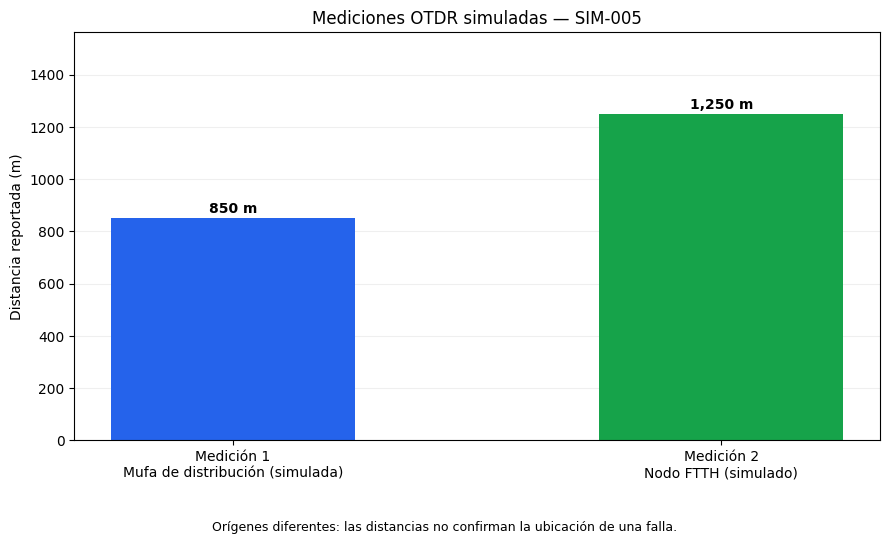

Gráfico guardado: /content/EP2_resultados/EP2_SIM005_OTDR_DEMO.png


In [ ]:
import matplotlib.pyplot as plt

mediciones = resultado_c["historial_mediciones"]
nombres = [f"Medición {i}\n{m['origen']}" for i,m in enumerate(mediciones, 1)]
valores = [m["distancia_m"] for m in mediciones]
fig, ax = plt.subplots(figsize=(9, 5.5))
barras = ax.bar(nombres, valores, color=["#2563eb", "#16a34a"], width=0.5)
for bar, valor in zip(barras, valores):
    ax.text(bar.get_x()+bar.get_width()/2, valor+20, f"{valor:,.0f} m", ha="center", fontweight="bold")
ax.set_ylim(0, max(valores)*1.25)
ax.set_title("Mediciones OTDR simuladas — SIM-005")
ax.set_ylabel("Distancia reportada (m)")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.text(0.5, 0.025, "Orígenes diferentes: las distancias no confirman la ubicación de una falla.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.09, 1, 1])
ruta_png = CARPETA_RESULTADOS / "EP2_SIM005_OTDR_DEMO.png"
fig.savefig(ruta_png, dpi=170)
plt.show()
print("Gráfico guardado:", ruta_png)

In [ ]:
# Respaldo opcional de JSON y gráfico del caso simulado; evita sobreescribir sin intención.
RESPALDAR_GRAFICO_EN_DRIVE = False
if RESPALDAR_GRAFICO_EN_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    destino = Path("/content/drive/MyDrive/EP2_Agente_Inteligente_FTTH/Evidencias_Consolidado")
    destino.mkdir(parents=True, exist_ok=True)
    for origen in [Path(resultado_c["archivo_estado"]), ruta_png]:
        shutil.copy2(origen, destino / origen.name)
        print("Respaldado en Drive:", origen.name)
else:
    print("Respaldo adicional desactivado; ya existen evidencias previas en Google Drive.")

### 8.1. Resumen de evidencia de la ejecución real

En modo `real`, esta celda construye un resumen de los tres escenarios y lo guarda en Google Drive. Registra que **los tickets y mediciones son simulados**. No guarda reparaciones ni el contenido completo del RAG. Requiere Google Drive montado y se omite en `demo`.

La salida que figura debajo corresponde al respaldo realizado anteriormente en Colab. Para repetir el respaldo en una nueva sesión, primero autorizar el montaje de Drive.

In [ ]:
if MODO == "real":
    # EP2 - Evidencia de pruebas con RAG y Gemini reales

    import json
    from pathlib import Path
    from datetime import datetime, timezone

    print("=== RESPALDO DE PRUEBAS REALES EP2 ===")

    assert MODO == "real"

    pruebas = {}

    for nombre, resultado in [
        ("SIM-001", resultado_a),
        ("SIM-002", resultado_b),
        ("SIM-005", resultado_c)
    ]:
        pruebas[nombre] = {
            "ticket": resultado["ticket"],
            "ruta_supervisor": resultado["siguiente_paso"],
            "antecedentes_rag": len(resultado["antecedentes"]),
            "verificaciones": len(resultado["plan_revision"]),
            "mediciones_otdr": len(resultado["historial_mediciones"]),
            "validacion_otdr": resultado.get(
                "validacion_otdr", {}
            ).get("estado", "no_aplica"),
            "orientacion_generada": bool(
                resultado.get("respuesta_final", "").strip()
            )
        }

    assert pruebas["SIM-001"]["antecedentes_rag"] == 0
    assert pruebas["SIM-002"]["antecedentes_rag"] == 3
    assert pruebas["SIM-005"]["antecedentes_rag"] == 3
    assert pruebas["SIM-005"]["mediciones_otdr"] == 2
    assert pruebas["SIM-005"]["validacion_otdr"] == "origenes_diferentes"

    evidencia = {
        "proyecto": "EP2 Agente Inteligente FTTH",
        "fecha": datetime.now(timezone.utc).isoformat(),
        "modo_ejecucion": "real",
        "componentes": "LangGraph, Chroma y Gemini",
        "escenarios_simulados": True,
        "mediciones_otdr_simuladas": True,
        "pruebas": pruebas
    }

    from google.colab import drive
    drive.mount("/content/drive")

    destino = Path(
        "/content/drive/MyDrive/"
        "EP2_Agente_Inteligente_FTTH/"
        "Evidencias_Real_Consolidado"
    )

    destino.mkdir(parents=True, exist_ok=True)

    ruta = destino / "EP2_Pruebas_Reales_Consolidado.json"

    with open(ruta, "w", encoding="utf-8") as archivo:
        json.dump(
            evidencia,
            archivo,
            ensure_ascii=False,
            indent=4
        )

    assert ruta.exists()

    print("Archivo:", ruta.name)
    print("Pruebas registradas:", len(pruebas))
    print("Ubicación:", destino)
    print("\nEVIDENCIA REAL RESPALDADA CORRECTAMENTE")
else:
    print("Respaldo 8.1 omitido en modo demo. Solo se registran aquí pruebas reales.")


=== RESPALDO DE PRUEBAS REALES EP2 ===
Archivo: EP2_Pruebas_Reales_Consolidado.json
Pruebas registradas: 3
Ubicación: /content/drive/MyDrive/EP2_Agente_Inteligente_FTTH/Evidencias_Real_Consolidado

EVIDENCIA REAL RESPALDADA CORRECTAMENTE


## 9. Interpretación de evidencias y siguientes entregables

**Validaciones registradas en modo real:** integración LangGraph + Chroma + Gemini sobre 80 registros FTTH anonimizados; tres escenarios SIM-001, SIM-002 y SIM-005; consulta RAG, planificación, advertencia OTDR, generación de orientación, escritura JSON y comprobación de memoria temporal.

**Límites de la evidencia:** las incidencias y mediciones OTDR utilizadas son simuladas. Se probaron **reglas de decisión** y un flujo predefinido, no elección autónoma de herramientas por el LLM. La restauración desde JSON de estado completo se validó solamente en `demo`; los resúmenes JSON del modo real no constituyen una memoria persistente completa. El texto de Gemini es orientativo y necesita revisión humana.

**Aún por comprobar antes de declarar reproducibilidad completa:** instalación y ejecución desde una sesión Colab completamente limpia con versiones de biblioteca compatibles, suministro seguro del archivo fuente y permisos de API, más una nueva prueba acotada de la revisión del prompt OTDR. No se ha efectuado esa ejecución adicional en esta copia.

**Artefactos de entrega:** notebook, `requirements.txt` (verificar y fijar versiones probadas), diagrama Mermaid `docs/ARQUITECTURA.md`, `README.md`, evidencias anonimizadas y reporte académico. Las conclusiones y justificaciones técnicas personales corresponden al estudiante según las instrucciones de la EP2.

**Referencias de trabajo:** repositorio EP1 del proyecto, documentación oficial LangGraph, Chroma, Gemini e ITU-T G.984.1 (características generales GPON).

## Anexo A. Incidencia de compatibilidad de bibliotecas en Colab (bitácora histórica)

Durante el primer intento en modo real, `langchain_chroma` no pudo importarse porque OpenTelemetry tenía componentes antiguos cargados en memoria después de la instalación. Se comprobó lo siguiente:

| Verificación | Resultado observado |
|---|---|
| `chromadb` | 1.5.9 |
| `langchain-chroma` | 1.1.0 |
| `opentelemetry-sdk` | 1.45.2 |
| Constante `OTEL_LOGRECORD_ATTRIBUTE_COUNT_LIMIT` | Presente en el archivo instalado, pero ausente del módulo previamente cargado |
| Recarga parcial | Resolvió la primera constante, pero apareció otro `ImportError` |
| Reinicio de sesión Colab | Permitió volver a importar Chroma correctamente |

La documentación de este problema se conserva en el **notebook original del estudiante**. Se retiraron de la secuencia ejecutable las celdas de diagnóstico para no provocar recargas innecesarias ni errores al ejecutar este notebook desde el inicio. **No es una garantía de que cualquier entorno nuevo vaya a reproducir exactamente las versiones instaladas.**

## 10. Interfaz visual para demostración (opcional)

Esta sección requiere que las secciones 1 a 5 estén ejecutadas en la sesión actual. Genera una interfaz Gradio conectada a `grafo_ftth`; cada consulta invoca el flujo real y puede consumir cuota en modo real. En Colab el enlace es temporal y se protege con contraseña. No publicar enlaces, claves ni datos sensibles.


In [ ]:
# EP2 — Interfaz visual conectada al grafo existente (Gradio)
# REQUISITOS: ejecutar antes las secciones 1 a 5 del notebook consolidado.
# No ejecuta el agente durante su creación: solo cuando se pulsa «Analizar incidencia».

import uuid
import inspect
from getpass import getpass

try:
    import gradio as gr
except ImportError as exc:
    raise RuntimeError(
        "Falta Gradio. En una celda separada ejecuta: %pip install -q 'gradio>=5,<7'"
    ) from exc

requeridos = ["grafo_ftth", "estado_inicial", "MODO"]
faltantes = [nombre for nombre in requeridos if nombre not in globals()]
if faltantes:
    raise RuntimeError(
        "Primero ejecuta en orden las secciones 1 a 5 del notebook. "
        "Aún faltan estas variables: " + ", ".join(faltantes)
    )

# Historial de la demo SIM-005; son medidas FICTICIAS, no trazas de un OTDR real.
MEDICIONES_SIM005_UI = [
    {"distancia_m": 850.0, "origen": "Mufa de distribución (simulada)",
     "sentido": "Hacia CTO", "longitud_onda": "1550 nm"},
    {"distancia_m": 1250.0, "origen": "Nodo FTTH (simulado)",
     "sentido": "Hacia red de distribución", "longitud_onda": "1550 nm"},
]

EJEMPLO_CTO = "Clientes FTTH sin servicio. Se informa posible daño físico en caja CTO."


def ejemplo_ftth():
    return EJEMPLO_CTO, True


def consulta_visual(descripcion, sim005, mensajes):
    """Invoca el grafo real; no simula una respuesta conversacional."""
    mensajes = list(mensajes or [])
    pregunta = (descripcion or "").strip()
    if len(pregunta) > 1500:
        return mensajes, "Texto demasiado extenso.", "", "", ""

    mensajes.append({"role": "user", "content": pregunta or "(ticket sin descripción)"})
    historial = MEDICIONES_SIM005_UI if sim005 else []
    distancia = 1250.0 if sim005 else None
    identificador = "GUI-" + uuid.uuid4().hex[:10].upper()

    try:
        entrada = estado_inicial(identificador, pregunta, distancia=distancia, historial=historial)
        configuracion = {"configurable": {"thread_id": identificador}}
        resultado = grafo_ftth.invoke(entrada, config=configuracion)

        respuesta = resultado.get("respuesta_final", "") or "Sin orientación disponible."
        mensajes.append({"role": "assistant", "content": respuesta})

        ids = resultado.get("ids_antecedentes", [])
        antecedentes = ("**Casos recuperados:** " + ", ".join(f"`{x}`" for x in ids)
                        if ids else "**Casos recuperados:** ninguno (ticket incompleto)")
        pasos = resultado.get("plan_revision", [])
        plan = "\n".join(f"{i}. {paso}" for i, paso in enumerate(pasos, 1)) if pasos else "Sin planificación: falta describir el ticket."
        info_otdr = resultado.get("validacion_otdr", {}) or {}
        validacion = (f"**Estado:** `{info_otdr.get('estado', 'no_aplica')}`\n\n"
                      f"{info_otdr.get('advertencia', 'No se ejecutó la validación OTDR.')}")
        ruta = resultado.get("siguiente_paso", "")
        if ruta == "consultar_rag":
            flujo = "Supervisor → Consultar RAG → Planificar → Validar OTDR → Gemini/Orientación → Guardar JSON"
        else:
            flujo = "Supervisor → Solicitar información → Guardar JSON"
        seguimiento = (f"**Modo:** `{MODO}` · **Ticket:** `{identificador}`\n\n"
                       f"**Ruta ejecutada:** {flujo}\n\n"
                       "*Nodos elegidos por reglas programadas, no por razonamiento interno visible del LLM.*")
        return mensajes, antecedentes, plan, validacion, seguimiento
    except Exception as error:
        # No exponer en pantalla mensajes de error que puedan incluir información sensible.
        mensajes.append({"role": "assistant", "content":
                         "No se pudo completar la consulta. Revisa el error en Colab y la conexión/API."})
        print("Error de interfaz FTTH:", type(error).__name__)
        return mensajes, "Consulta no completada", "", "", "Error al ejecutar el grafo"


chatbot_opciones = {"type": "messages"} if "type" in inspect.signature(gr.Chatbot).parameters else {}

with gr.Blocks(title="EP2 | Agente Inteligente FTTH") as interfaz_ftth:
    gr.Markdown("# 🛰️ Agente Inteligente FTTH")
    gr.Markdown(
        "**EP2 · LangGraph + Chroma + Gemini**  |  "
        "Asistente de orientación para incidencias FTTH. "
        "**Demostración académica: solo datos ficticios o anonimizados.**"
    )
    gr.Markdown(
        f"**Ejecución actual: `{MODO}`.** "
        "En modo `real` consulta Chroma y genera texto con Gemini; "
        "en `demo` utiliza antecedentes y respuestas ficticias."
    )

    with gr.Row():
        with gr.Column(scale=3):
            conversacion = gr.Chatbot(label="Consulta al agente", height=410, **chatbot_opciones)
            texto = gr.Textbox(
                label="Describe el ticket o formula una consulta FTTH",
                placeholder="Ejemplo: Clientes FTTH sin servicio, posible daño en CTO...",
                lines=3,
            )
            ot = gr.Checkbox(
                label="Incluir mediciones OTDR SIM-005 (850 m y 1250 m; SIMULADAS)",
                value=False,
            )
            with gr.Row():
                ejemplo = gr.Button("Cargar ejemplo SIM-005", variant="secondary")
                ejecutar = gr.Button("Analizar incidencia", variant="primary")
        with gr.Column(scale=2):
            gr.Markdown("### Etapas y antecedentes")
            resumen_flujo = gr.Markdown("Aquí aparecerá la ruta del agente.")
            casos_recuperados = gr.Markdown("**Antecedentes:** pendientes.")
            gr.Markdown("### Plan de verificación")
            plan_revision_ui = gr.Markdown("El plan se mostrará después de analizar.")
            gr.Markdown("### Precaución OTDR")
            estado_otdr_ui = gr.Markdown("Aún no se ha analizado el ticket.")

    ejemplo.click(fn=ejemplo_ftth, inputs=[], outputs=[texto, ot])
    ejecutar.click(
        fn=consulta_visual,
        inputs=[texto, ot, conversacion],
        outputs=[conversacion, casos_recuperados, plan_revision_ui, estado_otdr_ui, resumen_flujo],
    )
    gr.Markdown(
        "**Nota:** el historial de mensajes es visual; cada consulta genera un ticket "
        "independiente. La herramienta no simula razonamientos internos del modelo, "
        "no interpreta trazas instrumentales y no reemplaza las decisiones en terreno."
    )

# En Colab share=True crea una URL temporal accesible desde Internet:
# la contraseña impide el acceso anónimo. No compartir URL ni credenciales.
clave_ui = getpass("Crea una contraseña TEMPORAL para la interfaz (8 caracteres o más): ")
if len(clave_ui) < 8:
    raise ValueError("Usa una contraseña temporal de al menos 8 caracteres.")

interfaz_ftth.launch(share=True, auth=("supervisor", clave_ui), inline=False, show_error=False)
